# Rhode Island and the timing of an effect

A July 2003 court decision effectively decriminalized indoor sex work in Rhode Island. Did female gonorrhea incidence depart from its synthetic control, and in which years? Chernozhukov, Wüthrich and Zhu revisit Cunningham and Shah’s data to illustrate how conformal inference can answer both questions. This notebook reproduces the moving-block synthetic control results in their Tables 1 and 2 and Figure 5. [Conformal inference paper](https://doi.org/10.1080/01621459.2021.1920957) · [Original empirical study](https://doi.org/10.1093/restud/rdx065)

In [1]:
%matplotlib inline
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from pysynth import (
    Panel, SyntheticControl, conformal_confidence_set, conformal_test,
    plot_conformal_set, plot_paths, save_figure,
)
from pysynth.datasets import DATASETS, load_dataset
from pysynth.plotting import LITERATURE

cwd = Path.cwd()
root = cwd.parent if cwd.name == 'empirical_examples' else cwd
name = 'rhode_island'
output_dir = root / 'outputs' / 'empirical_examples' / name
output_dir.mkdir(parents=True, exist_ok=True)

def export_table(table, suffix, **kwargs):
    table.to_csv(output_dir / f'{name}-{suffix}.csv', **kwargs)

def export_figure(fig, suffix):
    save_figure(fig, output_dir / f'{name}-{suffix}')

versions = pd.Series(
    {p: version(p) for p in ['pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib']},
    name='version',
).rename_axis('package')
export_table(versions, 'versions')

## The outcome and comparison states

The authors supply 25 annual observations of log female gonorrhea incidence per 100,000. Their analysis uses 1985–2003 to fit the comparison and 2004–2009 to measure effects. Rhode Island is the first series in the archive. The remaining 50 series cover the other states and the District of Columbia under the authors’ anonymous column identifiers. The loader downloads the versioned ZIP using `requests`, verifies its SHA-256 digest and reads the log outcome directly from memory. [Journal replication archive, version 1](https://doi.org/10.6084/m9.figshare.14473870.v1)

In [2]:
spec = DATASETS[name]
panel = spec.panel(load_dataset(name, timeout=60))
assert (panel.n_control, panel.n_pre, panel.n_post) == (50, 19, 6)
assert panel.times.tolist() == list(range(1985, 2010))
print(f'{panel.n_control} donors · {panel.n_pre} pre-treatment years · {panel.n_post} post-treatment years')

50 donors · 19 pre-treatment years · 6 post-treatment years


## Was there a departure from the synthetic control?

The Table 2 null says that the effect was zero **in every year** from 2004 through 2009. Impose that null and fit nonnegative, unit-sum donor weights on all 25 annual observations. Sum the absolute residuals over the six post-treatment years, then move that six-year window through every cyclic position, including windows that wrap around to 1985. The p-value is the fraction of windows scoring at least as high as the observed window.

Table 1 applies the same diagnostic to the last one, two or three years of the **pre-treatment** sample. The last observation in each of those three analyses is 2003. [Published Tables 1–2](https://arxiv.org/pdf/1712.09089#page=40)

In [3]:
joint = conformal_test(panel)
pre = panel.n_pre
checks = []
rotations = []

def record(test, table, first, last, paper):
    tail = int(test.rotations.at_least_observed.sum())
    total = len(test.rotations)
    checks.append({
        'paper_table': table, 'first_year': first, 'last_year': last,
        'tail_windows': tail, 'all_windows': total,
        'python_p': test.p_value, 'published_p': paper,
    })
    rotations.append(test.rotations.reset_index().assign(
        paper_table=table, first_year=first, last_year=last,
    ))

for h, paper_p in [(1, 0.32), (2, 0.32), (3, 0.26)]:
    placebo = Panel(panel.y[:pre], panel.n_control, pre - h, panel.times[:pre], panel.units)
    record(conformal_test(placebo), 1, panel.times[pre - h], panel.times[pre - 1], paper_p)
record(joint, 2, panel.times[pre], panel.times[-1], 0.04)

tests = pd.DataFrame(checks)
np.testing.assert_array_equal(tests.python_p.round(2), tests.published_p)
np.testing.assert_array_equal(tests.tail_windows, [6, 6, 5, 1])
export_table(tests, 'published-tests', index=False)
export_table(pd.concat(rotations, ignore_index=True), 'cyclic-windows', index=False)
test_table = pd.DataFrame({
    'Paper table': tests.paper_table,
    'Tested years': [str(a) if a == b else f'{a}–{b}' for a, b in zip(tests.first_year, tests.last_year)],
    'Tail rank': [f'{a} / {b}' for a, b in zip(tests.tail_windows, tests.all_windows)],
    'PySynthCon p': tests.python_p, 'Published p': tests.published_p,
})
display(test_table.style.set_uuid('rhode-joint').hide(axis='index').format({
    'PySynthCon p': '{:.4f}', 'Published p': '{:.2f}',
}))

Paper table,Tested years,Tail rank,PySynthCon p,Published p
1,2003,6 / 19,0.3158,0.32
1,2002–2003,6 / 19,0.3158,0.32
1,2001–2003,5 / 19,0.2632,0.26
2,2004–2009,1 / 25,0.0400,0.04


## What does a pre-treatment fit predict?

The solid and dashed paths below use one ordinary SCM fit. Here the donor weights use 1985–2003 only. These weights generate the diamonds in the next figure. The journal’s own central markers show the mean of each year’s accepted grid candidates. The null-imposed fits used to calculate p-values have a different fitting window.

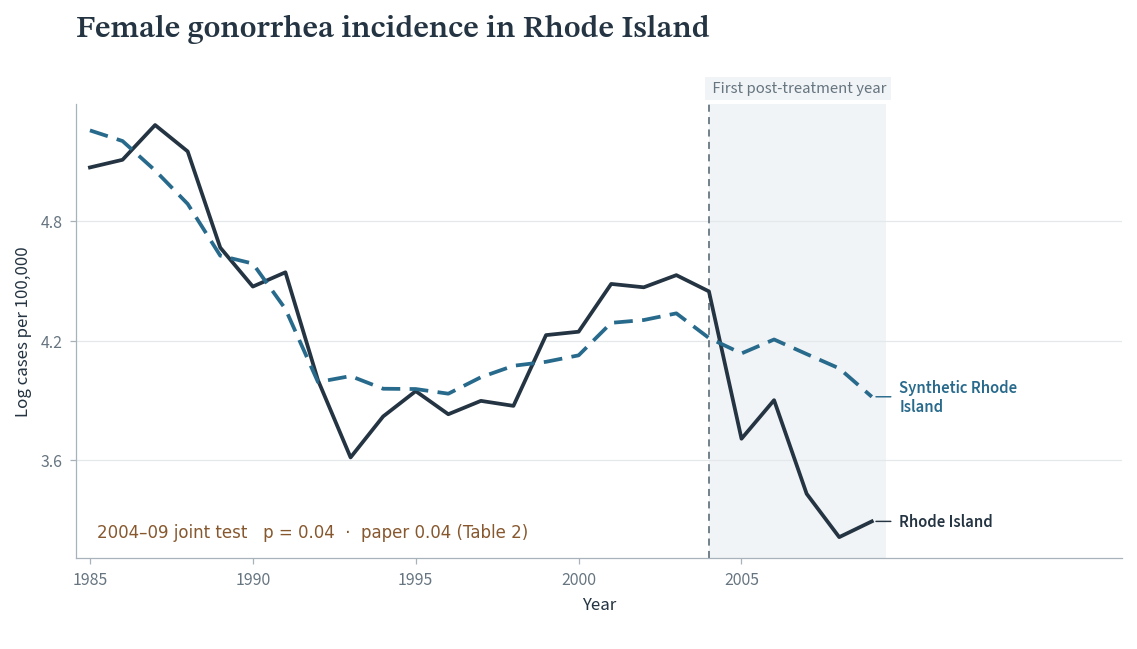

In [4]:
fit = SyntheticControl().fit(panel)
path = fit.to_frame()[['counterfactual', 'effect', 'post']]
export_table(path, 'synthetic-path', index_label='year')
export_table(fit.weights.rename('pre_fit_weight'), 'donor-weights', index_label='source_column')

ax = plot_paths(
    fit, title='Female gonorrhea incidence in Rhode Island',
    ylabel='Log cases per 100,000', xlabel='Year', observed_label='Rhode Island',
    counterfactual_label='Synthetic Rhode Island', intervention_label='First post-treatment year',
    figsize=(7.5, 4.25),
)
ax.text(
    0.02, 0.035,
    f'2004–09 joint test   p = {joint.p_value:.2f}  ·  paper {tests.published_p.iloc[-1]:.2f} (Table 2)',
    transform=ax.transAxes, fontsize=8, color=LITERATURE, va='bottom',
    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 2},
)
export_figure(ax.figure, 'paths')

## Which annual effects fit the data?

Figure 5 tests 701 candidate effects per year, from −5.00 to 2.00 log points in steps of 0.01. For each candidate, subtract it from the observed outcome for that year, append the adjusted observation to the 19 pre-treatment years, and refit the donor weights. Each year’s 90% pointwise set contains every candidate with p > 0.10. The 4,206 fits below retain every p-value, including those for rejected candidates. [Figure 5, synthetic control panel](https://arxiv.org/pdf/1712.09089#page=39)

In [5]:
alpha = 0.10
candidates = np.arange(-500, 201) / 100
grid = conformal_confidence_set(panel, candidates, alpha=alpha)
assert len(grid) == len(candidates) * panel.n_post == 4206
export_table(grid.assign(alpha=alpha), 'pointwise-grid', index=False)

# Numerical endpoints from an independent execution of the journal archive's
# sc() and ci() functions on this grid. Figure 5 displays the sets graphically.
post_years = panel.times[pre:]
reference = pd.DataFrame({
    'lower': [-0.26, -0.86, -0.81, -1.16, -1.46, -1.31],
    'upper': [ 0.70, -0.01,  0.17, -0.33, -0.33, -0.19],
}, index=post_years)
accepted = grid.loc[grid.accepted]
limits = accepted.groupby('time').candidate.agg(['min', 'max', 'size'])
np.testing.assert_array_equal(limits[['min', 'max']].to_numpy(), reference.to_numpy())
# The original R run accepted every grid point between its endpoints for these six years.
# Test every grid decision as well as each endpoint.
reference_per_row = reference.loc[grid.time]
np.testing.assert_array_equal(grid.accepted, (
    (grid.candidate.to_numpy() >= reference_per_row.lower.to_numpy()) &
    (grid.candidate.to_numpy() <= reference_per_row.upper.to_numpy())
))
authors_gap = pd.Series(
    [0.23374510168, -0.42786606852, -0.30438218534, -0.70094748576, -0.84661320243, -0.62514656230],
    index=post_years, name='authors_R_SCM_gap',
)
np.testing.assert_allclose(fit.effects.loc[post_years], authors_gap, atol=5e-5, rtol=0)
yearly = pd.concat([
    fit.effects.loc[post_years].rename('SCM_gap'), limits.rename(
        columns={'min': 'grid_lower', 'max': 'grid_upper', 'size': 'accepted_points'}),
    reference.add_prefix('authors_R_'), authors_gap,
    accepted.groupby('time').candidate.mean().rename('figure_5_marker'),
    grid.loc[grid.candidate.eq(0)].set_index('time').accepted.rename('accepts_zero'),
], axis=1)
export_table(yearly, 'figure-5-checks', index_label='year')
def grid_span(lower, upper):
    return [f'{lo:.2f} … {hi:.2f}'.replace('-', '−') for lo, hi in zip(lower, upper)]

figure_table = pd.DataFrame({
    'Pre-fit SCM gap': yearly.SCM_gap, 'Figure 5 center': yearly.figure_5_marker,
    'Accepted grid limits': grid_span(yearly.grid_lower, yearly.grid_upper),
    'Archive limits': grid_span(yearly.authors_R_lower, yearly.authors_R_upper),
    'Includes zero': yearly.accepts_zero.map({True: 'Yes', False: 'No'}),
}).rename_axis('Year')
display(figure_table.style.set_uuid('rhode-annual').format({
    'Pre-fit SCM gap': '{:.2f}', 'Figure 5 center': '{:.2f}',
}))

,Pre-fit SCM gap,Figure 5 center,Accepted grid limits,Archive limits,Includes zero
Year,,,,,
2004,0.23,0.22,−0.26 … 0.70,−0.26 … 0.70,Yes
2005,-0.43,-0.43,−0.86 … −0.01,−0.86 … −0.01,No
2006,-0.30,-0.32,−0.81 … 0.17,−0.81 … 0.17,Yes
2007,-0.70,-0.74,−1.16 … −0.33,−1.16 … −0.33,No
2008,-0.85,-0.90,−1.46 … −0.33,−1.46 … −0.33,No
2009,-0.63,-0.75,−1.31 … −0.19,−1.31 … −0.19,No


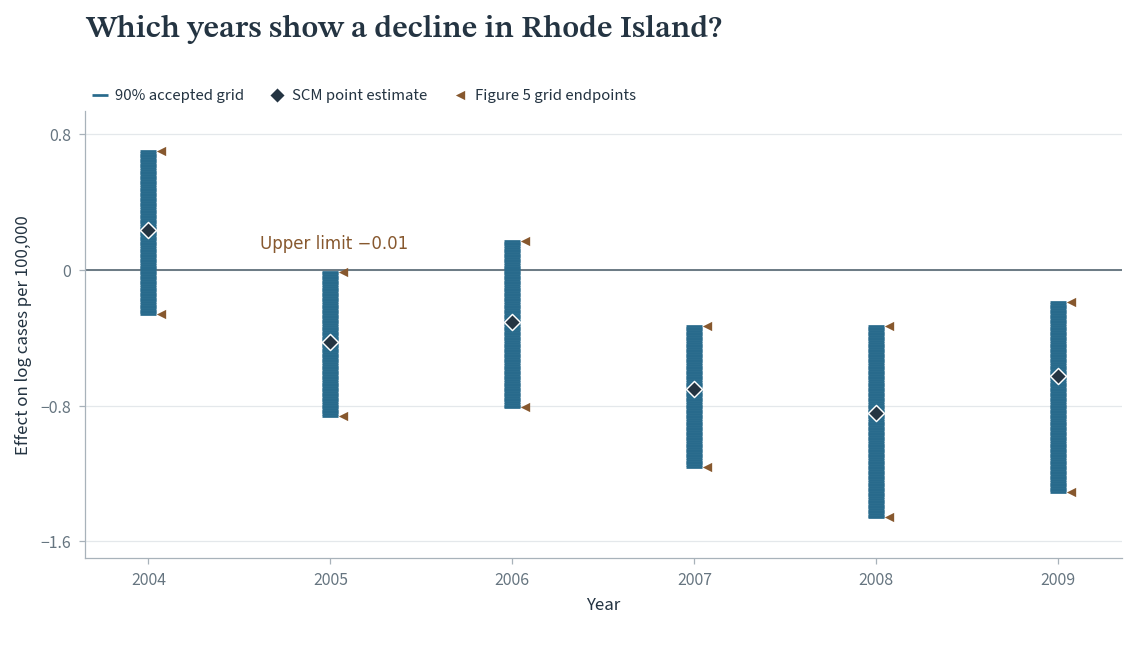

In [6]:
fig, ax = plot_conformal_set(
    grid, fit, reference_bounds=reference, reference_label='Figure 5 grid endpoints',
    title='Which years show a decline in Rhode Island?',
    xlabel='Year', ylabel='Effect on log cases per 100,000',
    figsize=(7.5, 4.25),
)
upper_2005 = reference.loc[2005, 'upper']
ax.annotate(
    f'Upper limit {upper_2005:.2f}'.replace('-', '−'), (2005, upper_2005),
    xytext=(2, 9), textcoords='offset points', fontsize=8, color=LITERATURE,
    ha='center', va='bottom',
)
export_figure(fig, 'pointwise-sets')

The six-year joint test ranks first among 25 cyclic positions. For individual years, zero lies in the accepted set in 2004 and 2006. The upper accepted candidate for 2005 falls just below zero at −0.01 log points. All accepted candidates in 2007–2009 are negative. Each annual set has a pointwise interpretation; a simultaneous claim about all six annual magnitudes would require joint coverage. Finite-sample validity of the permutation test depends on invariance under the chosen shifts. The paper gives conditions for approximate validity with serial dependence. [Theory and application](https://doi.org/10.1080/01621459.2021.1920957)

The figure’s endpoint markers and numerical reference checks come from an independent run of the journal archive’s `sc` and `ci` functions using `limSolve` 2.0.3 (type 2). All 4,206 accept/reject decisions agree. The published central-marker calculation, the mean of the accepted candidates, appears in the `figure_5_marker` column. The separately fitted pre-treatment forecasts agree with the R code to 0.000024 log points. All regenerated tables and figures are in `outputs/empirical_examples/rhode_island/`. [Authors’ inference code](https://github.com/kwuthrich/scinference/blob/567c6889ce0a1d269a62d415b88aa6baf723a3fe/R/conformal.R) · [Authors’ SCM fit](https://github.com/kwuthrich/scinference/blob/567c6889ce0a1d269a62d415b88aa6baf723a3fe/R/estimators.R)